In [124]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import sklearn.cluster
kmeans = sklearn.cluster.KMeans

In [125]:
from sklearn.datasets import load_iris
data=load_iris()
df=pd.DataFrame(data.data,columns=data.feature_names)

In [126]:
df.isnull().sum()   

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

In [127]:
df=df.drop(columns=['sepal width (cm)','sepal length (cm)'])

In [128]:
kmeans = sklearn.cluster.KMeans(n_clusters=3)

In [129]:
y_kmeans = kmeans.fit_predict(df)

In [130]:
y_kmeans

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=int32)

In [131]:
df['cluster'] = y_kmeans

In [132]:
# Option A: Reassigning to the dataframe
df = df.rename(columns={'petal length (cm)': 'petal_length_(cm)', 'petal width (cm)': 'petal_width_(cm)'})


In [133]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[['petal_length_(cm)', 'petal_width_(cm)']])
df1=df[df.cluster==0]
df2=df[df.cluster==1]
df3=df[df.cluster==2]

In [134]:
df_scaled = pd.DataFrame(df_scaled, columns=['petal_length_(cm)', 'petal_width_(cm)'])

In [135]:
df_scaled.head()

,petal_length_(cm),petal_width_(cm)
0,-1.340227,-1.315444
1,-1.340227,-1.315444
2,-1.397064,-1.315444
3,-1.283389,-1.315444
4,-1.340227,-1.315444


In [136]:
mse = []
for k in range(1, 11):
    km = sklearn.cluster.KMeans(n_clusters=k)
    km.fit(df_scaled)
    mse.append(km.inertia_)

In [137]:
print(mse)

[300.0, 54.16878133149558, 18.026962612544075, 12.283372197379126, 9.14533766127183, 7.971584734948237, 6.001705015322092, 5.230626733230915, 4.9659026525657275, 4.4434128451271055]


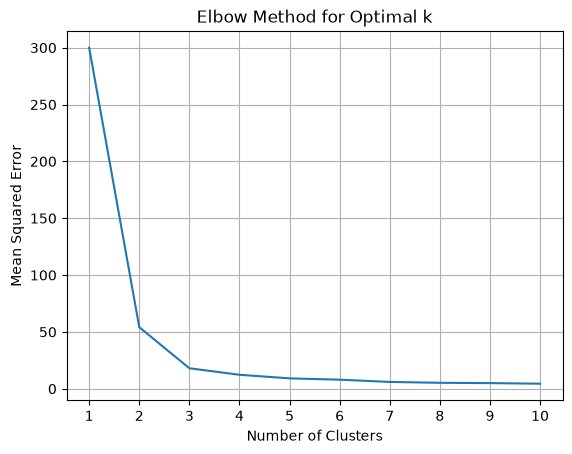

In [153]:
plt.plot(range(1, 11), mse)
plt.xlabel('Number of Clusters')
plt.ylabel('Mean Squared Error')
plt.title('Elbow Method for Optimal k')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [139]:
print(kmeans.cluster_centers_.shape)


(3, 2)


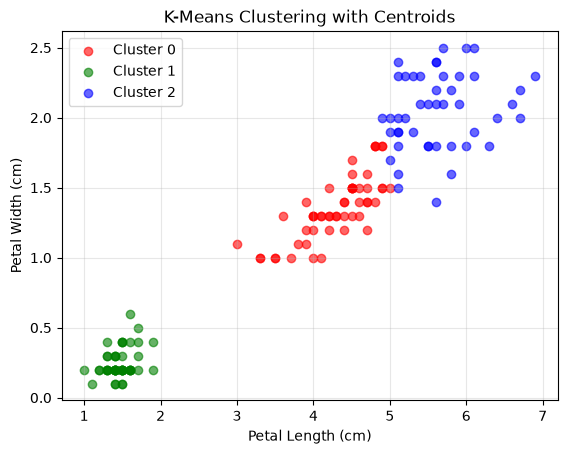

In [152]:
# Get cluster centers in original scale
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot clusters
plt.scatter(
    df1['petal_length_(cm)'],
    df1['petal_width_(cm)'],
    c='red',
    label='Cluster 0',
    alpha=0.6
)

plt.scatter(
    df2['petal_length_(cm)'],
    df2['petal_width_(cm)'],
    c='green',
    label='Cluster 1',
    alpha=0.6
)

plt.scatter(
    df3['petal_length_(cm)'],
    df3['petal_width_(cm)'],
    c='blue',
    label='Cluster 2',
    alpha=0.6
)

# Plot centroids


plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('K-Means Clustering with Centroids')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [154]:
from sklearn.feature_extraction.text import TfidfVectorizer

messages = [
    "Congratulations you won a free prize",
    "Hello how are you",
    "Free offer click now",
    "Hello friend"
]

vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(messages)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['are' 'click' 'congratulations' 'free' 'friend' 'hello' 'how' 'now'
 'offer' 'prize' 'won' 'you']
[[0.         0.         0.48546061 0.38274272 0.         0.
  0.         0.         0.         0.48546061 0.48546061 0.38274272]
 [0.55528266 0.         0.         0.         0.         0.43779123
  0.55528266 0.         0.         0.         0.         0.43779123]
 [0.         0.52547275 0.         0.41428875 0.         0.
  0.         0.52547275 0.52547275 0.         0.         0.        ]
 [0.         0.         0.         0.         0.78528828 0.6191303
  0.         0.         0.         0.         0.         0.        ]]
